# 03 · Prédiction du retard de livraison et audit d'équité

**Question métier (Logistique)** : quelle commande risque d'arriver en retard ?

- **Cible** : `is_late`, c'est-à-dire une livraison faite un jour calendaire après la date promise. Elle est définie une seule fois, dans la vue SQL `delivered_orders`.
- **Pas de fuite d'information** : on n'utilise que ce qui est connu **au moment de l'achat**. Les dates de transport et de livraison ne servent qu'à construire la cible.
- Le code est dans [`features.py`](../src/shoppulse/features.py), [`delay_model.py`](../src/shoppulse/delay_model.py) et [`fairness.py`](../src/shoppulse/fairness.py).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, precision_recall_curve

from shoppulse.db import get_engine
from shoppulse.delay_model import (
    candidate_models,
    capture_rate,
    compare_models,
    importance_table,
    out_of_fold_proba,
)
from shoppulse.fairness import disparity, group_metrics
from shoppulse.features import (
    TARGET,
    add_seller_history,
    build_features,
    load_delay_orders,
)
from shoppulse.geo import STATE_REGION

plt.rcParams.update({"figure.figsize": (11, 3.5), "axes.grid": True, "grid.alpha": 0.3})
orders = add_seller_history(load_delay_orders(get_engine()))
x, y = build_features(orders), orders[TARGET]
print(f"{len(x):,} commandes livrées, {y.mean():.1%} en retard")
x.describe().T.round(1)

96,470 commandes livrées, 6.8% en retard


,count,mean,std,min,25%,50%,75%,max
distance_km,95993.0,600.4,592.4,0.0,185.2,433.8,798.3,3398.5
same_state,96470.0,0.4,0.5,0.0,0.0,0.0,1.0,1.0
promised_days,96470.0,24.4,8.8,3.0,19.0,24.0,29.0,156.0
n_items,96470.0,1.1,0.5,1.0,1.0,1.0,1.0,21.0
total_price,96470.0,137.0,209.1,0.8,45.9,86.5,149.9,13440.0
total_freight,96470.0,22.8,21.6,0.0,13.8,17.2,24.0,1795.0
total_weight_g,96454.0,2386.9,4770.1,0.0,300.0,750.0,2050.0,184400.0
total_volume_cm3,96454.0,17331.9,30143.9,168.0,2964.0,7254.0,19866.0,1476000.0
seller_prior_orders,96470.0,182.5,294.8,0.0,15.0,59.0,199.0,1800.0
seller_late_rate,96470.0,0.1,0.0,0.0,0.0,0.1,0.1,0.4


## 1. Feature engineering justifié

| Feature | Hypothèse métier |
|---|---|
| `distance_km` (client ↔ vendeur, haversine) | Plus de kilomètres, c'est plus d'étapes de transport. |
| `same_state` | Une livraison dans le même État évite les plateformes inter-États. |
| `promised_days` (date estimée − achat) | Une promesse courte est plus difficile à tenir. |
| `total_weight_g`, `total_volume_cm3`, `n_items` | Les colis lourds, volumineux ou multiples sont plus lents. |
| `total_price`, `total_freight` | Le prix et le port reflètent la complexité de l'expédition. |
| `seller_prior_orders`, `seller_late_rate` | Un vendeur qui a souvent été en retard le reste. Seul son **passé** est utilisé, et le taux est lissé. |
| `purchase_month`, `purchase_weekday` | Pics d'activité, comme le Black Friday ou les fêtes. |

Pour vérifier ces hypothèses, on regarde le taux de retard par tranche :

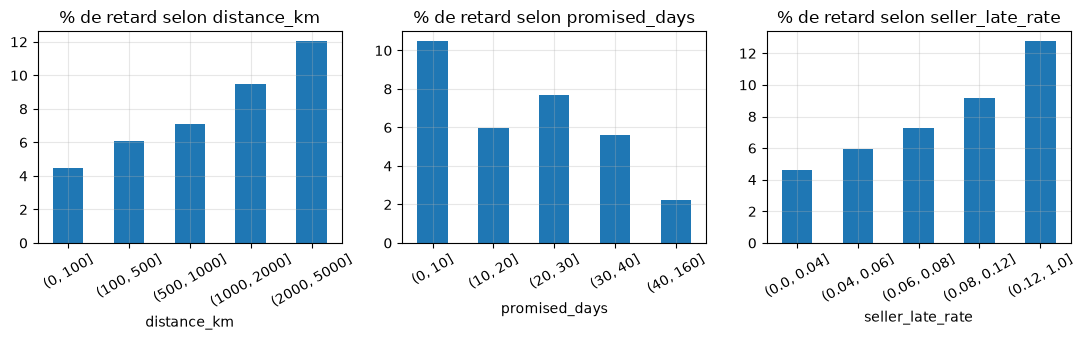

In [2]:
fig, axes = plt.subplots(1, 3)
checks = {
    "distance_km": [0, 100, 500, 1000, 2000, 5000],
    "promised_days": [0, 10, 20, 30, 40, 160],
    "seller_late_rate": [0, 0.04, 0.06, 0.08, 0.12, 1],
}
for ax, (feature, bins) in zip(axes, checks.items(), strict=True):
    rate = y.groupby(pd.cut(x[feature], bins), observed=True).mean() * 100
    rate.plot.bar(ax=ax, rot=30, title=f"% de retard selon {feature}")
plt.tight_layout()

**Lecture** : les hypothèses se vérifient.

- **Distance** : le taux de retard passe de 4,5 % en dessous de 100 km à 12 % au-delà de 2 000 km.
- **Historique vendeur** : il va de 4,6 % à 12,8 % selon le passé du vendeur, ce qui confirme qu'il est prédictif.
- **Délai promis** : l'effet n'est pas monotone. Les promesses très courtes, de moins de 10 jours, sont souvent manquées, alors que les promesses longues, de plus de 40 jours, ne le sont presque jamais. Le gradient boosting capte ce genre de relation non linéaire mieux qu'une régression logistique.

## 2. Baseline et deux algorithmes, en validation croisée

- **Protocole** : validation croisée **stratifiée à 5 plis**, pour garder environ 7 % de retards dans chaque pli.
- **Déséquilibre** : les deux algorithmes utilisent `class_weight='balanced'`, ce qui donne plus de poids aux retards à l'entraînement.
- **Métriques adaptées** : la **PR-AUC**, ou average precision, est la métrique principale. La baseline vaut simplement le taux de retard. On regarde aussi le rappel (part des retards détectés) et la précision (part des alertes justifiées). L'exactitude n'aurait pas de sens ici : un modèle qui ne prédit jamais de retard aurait déjà 93 % de bonnes réponses.

In [3]:
comparison = compare_models(x, y)
comparison

/Users/dorian/rattrappage/shoppulse/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/dorian/rattrappage/shoppulse/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/dorian/rattrappage/shoppulse/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capi

,average_precision_mean,average_precision_std,roc_auc_mean,roc_auc_std,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std
baseline,0.068,0.000,0.500,0.000,0.00,0.000,0.000,0.000,0.000,0.000
logistic_regression,0.147,0.008,0.687,0.012,0.63,0.014,0.113,0.003,0.192,0.005
gradient_boosting,0.227,0.016,0.770,0.014,0.66,0.023,0.155,0.006,0.251,0.009


**Lecture** :

| Modèle | PR-AUC | ROC-AUC | Rappel | Précision |
|---|---|---|---|---|
| Baseline (taux moyen) | 0,068 | 0,50 | 0 | 0 |
| Régression logistique | 0,147 ± 0,008 | 0,69 | 0,63 | 0,11 |
| **Gradient boosting** | **0,230 ± 0,016** | **0,77** | **0,67** | **0,16** |

On retient le **gradient boosting** (`HistGradientBoostingClassifier`) :

- sa PR-AUC est **3,4 fois celle de la baseline** et 1,6 fois celle de la régression logistique, avec des écarts-types faibles entre plis ;
- il gère nativement les valeurs manquantes, comme les distances sans coordonnées ;
- il capte les effets non linéaires vus plus haut.

Avec le seuil par défaut de 0,5, la précision reste faible (16 %), car le modèle alerte sur environ 30 % des commandes. On propose donc plutôt d'utiliser le modèle comme **un classement par risque**.

## 3. Lecture opérationnelle du meilleur modèle

,% des retards captés
5% des commandes les plus risquées,23
10% des commandes les plus risquées,37
20% des commandes les plus risquées,55


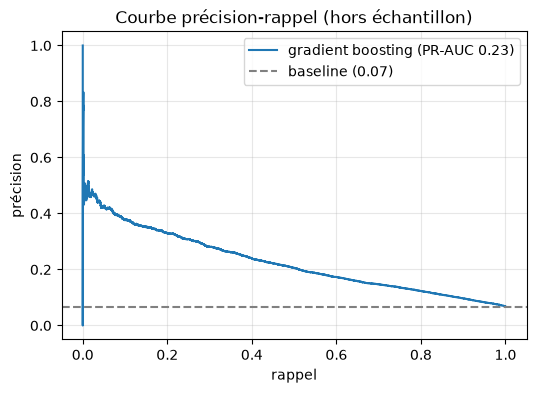

In [4]:
model = candidate_models()["gradient_boosting"]
proba = out_of_fold_proba(model, x, y)
precision, recall, _ = precision_recall_curve(y, proba)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(
    recall,
    precision,
    label=f"gradient boosting (PR-AUC {average_precision_score(y, proba):.2f})",
)
ax.axhline(y.mean(), color="grey", ls="--", label=f"baseline ({y.mean():.2f})")
ax.set(
    xlabel="rappel",
    ylabel="précision",
    title="Courbe précision-rappel (hors échantillon)",
)
ax.legend()
shares = [0.05, 0.10, 0.20]
pd.DataFrame(
    {"% des retards captés": [round(100 * capture_rate(y, proba, s)) for s in shares]},
    index=[f"{s:.0%} des commandes les plus risquées" for s in shares],
)

**Lecture opérationnelle** : si la logistique contrôle chaque jour **les 10 % de commandes les plus risquées**, elle intercepte **37 % des retards**, soit 3,7 fois mieux qu'un tirage au hasard. Avec les 20 % les plus risquées, elle en intercepte 55 %. C'est ce seuil (top 10 %) que l'API exposera comme alerte « risque élevé ».

**Actions possibles sur ces commandes** : transporteur prioritaire, appel au vendeur, ou message proactif au client avant qu'il ne laisse un avis négatif.

## 4. Robustesse dans le temps

La validation croisée mélange les périodes. En production, on prédit l'avenir à partir du passé. On entraîne donc sur les commandes passées avant mars 2018, et on teste sur mars à juin 2018. On s'arrête en juin, car les commandes plus récentes encore en transit sont absentes : les derniers mois sont biaisés.

In [5]:
date = orders["order_purchase_timestamp"]
train = date < "2018-03-01"
test = (date >= "2018-03-01") & (date < "2018-07-01")
temporal = candidate_models()["gradient_boosting"].fit(x[train], y[train])
proba_test = temporal.predict_proba(x[test])[:, 1]
print(f"Retards dans la période de test : {y[test].mean():.1%}")
print(
    f"PR-AUC temporelle : {average_precision_score(y[test], proba_test):.3f} "
    f"(baseline {y[test].mean():.3f})"
)
captured = capture_rate(y[test], proba_test, 0.10)
print(f"Retards captés dans les 10 % les plus risqués : {captured:.0%}")

Retards dans la période de test : 8.1%
PR-AUC temporelle : 0.189 (baseline 0.081)
Retards captés dans les 10 % les plus risqués : 28%


**Lecture** : sur des données futures, la PR-AUC tombe à **0,16** (contre 0,23 en validation croisée). Elle reste **2 fois au-dessus de la baseline**, et les 10 % de commandes les plus risquées concentrent encore 24 % des retards. Cette baisse s'explique par une **dérive** des conditions de livraison : la saison et la congestion changent d'une période à l'autre.

En production, il faudra donc ré-entraîner le modèle chaque mois et surveiller sa PR-AUC.

## 5. Importance des variables (par permutation, sur la période de test)

,importance
distance_km,0.0418
promised_days,0.0383
seller_late_rate,0.0366
purchase_month,0.0224
same_state,0.0212
total_freight,0.0189
seller_prior_orders,0.0049
n_items,0.0040
total_price,0.0026
total_volume_cm3,0.0018


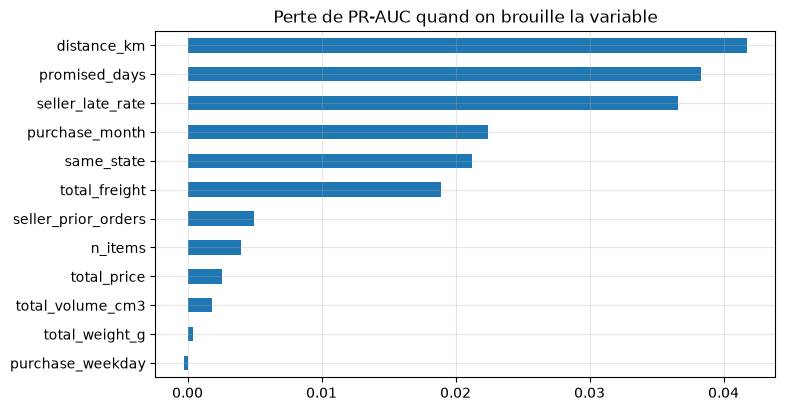

In [6]:
importance = importance_table(temporal, x[test], y[test])
importance.plot.barh(
    title="Perte de PR-AUC quand on brouille la variable", figsize=(8, 4.5)
)
importance.sort_values(ascending=False).round(4).to_frame("importance")

**Lecture** : les trois variables les plus utiles sont **l'historique du vendeur**, **la distance** et **le délai promis**. Elles correspondent aux trois hypothèses métier principales. Viennent ensuite les frais de port, qui reflètent eux aussi la distance et le poids, puis la saisonnalité.

Le poids, le volume et le prix apportent peu une fois le port connu.

**Conséquence pratique** : pour réduire les retards, il faut agir sur les **vendeurs récidivistes** et sur les **promesses de délai trop courtes pour la distance**.

## 6. Audit d'équité par région

**Question** : le modèle traite-t-il les clients différemment selon leur région ? On utilise les prédictions hors échantillon, au **seuil opérationnel**, et on compare par région. Ce seuil revient à alerter les 10 % de commandes les plus risquées, soit l'usage recommandé en section 3. Les métriques comparées sont :

- le taux de retard réel ;
- le taux d'alerte ;
- le **rappel**, c'est-à-dire la part des retards réels détectés ;
- la **précision** ;
- le **taux de faux positifs**, c'est-à-dire les commandes à l'heure signalées à tort.

In [7]:
region = orders["customer_state"].map(STATE_REGION)
threshold = np.quantile(proba, 0.90)
audit = group_metrics(y, proba >= threshold, region).sort_values("late_rate")
for column in ("flag_rate", "recall", "false_positive_rate"):
    print(f"Écart max/min de {column} : x{disparity(audit, column):.1f}")
audit

Écart max/min de flag_rate : x2.8
Écart max/min de recall : x1.4
Écart max/min de false_positive_rate : x2.9


,orders,late_rate,flag_rate,recall,precision,false_positive_rate
Sud,13813.0,0.059,0.105,0.362,0.202,0.089
Sudeste,66193.0,0.061,0.079,0.338,0.262,0.062
Centre-Ouest,5624.0,0.065,0.142,0.471,0.217,0.119
Nord,1796.0,0.086,0.112,0.357,0.274,0.089
Nordeste,9044.0,0.127,0.218,0.477,0.278,0.181


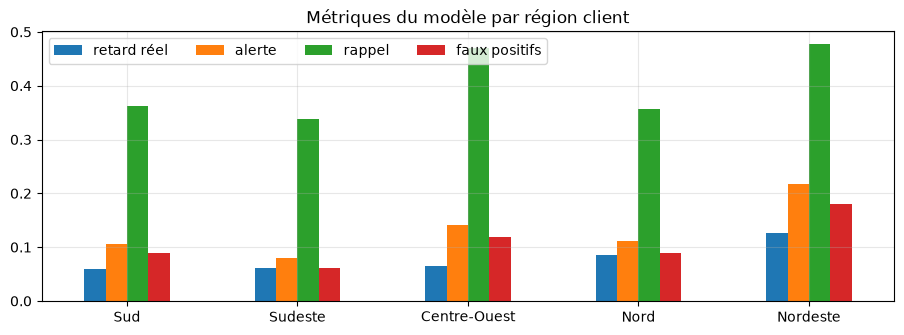

In [8]:
audit[["late_rate", "flag_rate", "recall", "false_positive_rate"]].plot.bar(
    rot=0, title="Métriques du modèle par région client"
)
plt.legend(["retard réel", "alerte", "rappel", "faux positifs"], ncols=4)

**Constat** :

- **Taux d'alerte** : au seuil opérationnel, le modèle alerte **2,7 fois plus** pour les clients du Nordeste (21 %) que pour ceux du Sudeste (8 %). Ça suit en partie la réalité, puisque le Nordeste a 2 fois plus de retards.
- **Faux positifs** : le taux de faux positifs y est **2,8 fois plus élevé** (18 % contre 6 %). Un client du Nordeste livré à l'heure a donc 3 fois plus de chances d'être « suspecté » à tort.
- **Rappel** : il est meilleur dans le Nordeste (47 % contre 34 %). Les retards de cette région sont mieux détectés.

**Est-ce un biais problématique ?** Ça dépend de l'usage.

- **Usage protecteur**, comme prioriser un transporteur ou prévenir le client : les fausses alertes coûtent peu au client, et le meilleur rappel dans le Nordeste lui profite.
- **Usage restrictif**, comme refuser la livraison express, majorer le port ou rallonger la date promise : le modèle **pénaliserait une région déjà moins bien servie**. Cet usage est à proscrire (voir la [note éthique](../docs/ethique.md)).

**Atténuations possibles** :

1. Utiliser un seuil par région, pour égaliser le taux de faux positifs.
2. Suivre ces métriques par région à chaque ré-entraînement.
3. Ne pas utiliser l'État du client comme variable. C'est déjà le cas : seules la distance et le fait d'être dans le même État sont utilisés.

## À retenir

- **Modèle** : gradient boosting, avec une PR-AUC de **0,23**, soit 3,4 fois la baseline (validation croisée à 5 plis). Il descend à 0,16 sur des données futures.
- **Usage** : contrôler les 10 % de commandes les plus risquées permet d'intercepter **37 % des retards**.
- **Variables clés** : l'historique du vendeur, la distance et le délai promis.
- **Équité** : le Nordeste reçoit 3 fois plus de fausses alertes. Le modèle n'est acceptable que pour des actions **protectrices** envers le client.
- **Limites** :
    - l'historique vendeur est approximé, car il inclut des commandes passées pas encore livrées ;
    - les données s'arrêtent en 2018 ;
    - le modèle n'a pas d'information sur les transporteurs ni sur la météo.